<a href="https://colab.research.google.com/github/willismax/MediaSystem-Python-Course/blob/main/13.Image-Processing/SMD_diffusion_tutorial.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 從擴散模型到少步生圖：SMD 實作教學

**多媒體系統｜生成式 AI 單元**

<a href="https://github.com/zjwfufu/SMD" target="_blank">SMD GitHub</a> ·
<a href="https://arxiv.org/abs/2610.18472" target="_blank">論文 arXiv:2610.18472</a> ·
<a href="https://huggingface.co/collections/zjwfufu/smd" target="_blank">Hugging Face 模型</a>

生圖模型（FLUX、Stable Diffusion、Qwen-Image…）背後都是**擴散模型**：從一團雜訊出發，一步步「去噪」成一張圖。
問題是：一般要走 **28～50 步**，每步還常要算兩次（CFG），很慢。

**SMD（Simplified Matching Distillation）** 是 2026 年 10 月發表的蒸餾方法，把大模型壓到 **只要 4 步** 就能出圖，而且部署時模型架構完全不變。

這本筆記本會帶你走一條完整的路：

| 部分 | 內容 | 需要 GPU？ | 時間 |
|---|---|---|---|
| **Part 1** | 擴散模型的直覺：加噪與去噪 | 不用 | 5 分鐘 |
| **Part 2** | 從零訓練一個迷你 flow matching 模型，並親手「蒸餾」成 4 步 | 不用（有更快） | 10 分鐘 |
| **Part 3** | 從玩具到真正的生圖模型：架構對照 | 不用 | 閱讀 |
| **Part 4** | 跑 SMD-FLUX.2-Klein-4B：4 步生圖 vs 原始模型 | **需要** | 20～30 分鐘 |
| **Part 5** | 總結與思考題 | — | — |

> 💡 **給學生的建議**：Part 1、2 是理解的核心，就算沒有 GPU 也一定要跑；Part 4 是「看到真東西」的獎勵關卡。

## 🔧 Part 0：環境準備

### 執行階段（Runtime）怎麼選？

到選單 **執行階段 → 變更執行階段類型**：

| GPU | Part 1–2 | Part 4（SMD 生圖） |
|---|---|---|
| CPU（免費） | ✅ 可以，稍慢 | ❌ 無法 |
| **T4**（免費） | ✅ | ⚠️ 可嘗試；T4 不原生支援 bfloat16，速度慢 |
| **L4**（Colab Pro） | ✅ | ✅ **建議** |
| A100（Colab Pro） | ✅ | ✅ 最快 |

Part 4 的基底模型約 16 GB，筆記本採用「**分兩階段載入**」（先只載文字編碼器，再只載去噪模型），讓一般 Colab 的記憶體也放得下。

In [3]:
#@title 檢查硬體
import torch, platform
print("PyTorch:", torch.__version__, "| Python:", platform.python_version())
if torch.cuda.is_available():
    p = torch.cuda.get_device_properties(0)
    print(f"GPU: {p.name}  |  VRAM: {p.total_memory/1024**3:.1f} GB  |  compute capability {p.major}.{p.minor}")
    if p.major < 8:
        print("⚠️ 這張卡不原生支援 bfloat16（例如 T4）。Part 1–2 沒問題；Part 4 可以試，但會比較慢。")
else:
    print("目前是 CPU 執行階段：Part 1–2 可以跑；Part 4 需要切換成 GPU。")

PyTorch: 2.11.0+cu130 | Python: 3.13.15
GPU: NVIDIA L4  |  VRAM: 22.0 GB  |  compute capability 8.9


In [4]:
#@title 安裝套件（約 1 分鐘）
# Part 1–2 只用到 Colab 內建的 torch / matplotlib。
# Part 4 需要較新版的 diffusers / transformers（版本對齊 SMD 官方 requirements.txt，但保留 Colab 內建的 torch）。
!pip install -q "diffusers==0.38.0" "transformers==5.17.0" "accelerate>=1.15" "peft>=0.21" "safetensors>=0.6" "huggingface_hub>=1.0" sentencepiece protobuf
print("✅ 安裝完成。若 Part 4 匯入時出錯，請「執行階段 → 重新啟動工作階段」後直接從 Part 4 開始跑（Part 4 是獨立的）。")

✅ 安裝完成。若 Part 4 匯入時出錯，請「執行階段 → 重新啟動工作階段」後直接從 Part 4 開始跑（Part 4 是獨立的）。


---
# 🌫️ Part 1：擴散模型的直覺

## 1.1 加噪很簡單：把圖和雜訊「混在一起」

現代生圖模型（FLUX、SD3、Qwen-Image）多半採用 **Flow Matching / Rectified Flow** 的寫法，概念比傳統 DDPM 更直白：

$$x_\sigma = (1-\sigma)\,x_0 + \sigma\,\varepsilon,\qquad \varepsilon \sim \mathcal{N}(0, I)$$

- $x_0$：乾淨的圖
- $\varepsilon$：純雜訊
- $\sigma \in [0, 1]$：雜訊比例（0 = 原圖，1 = 全雜訊）

就是在「圖」和「雜訊」之間畫一條直線，$\sigma$ 決定你站在線上的哪裡。

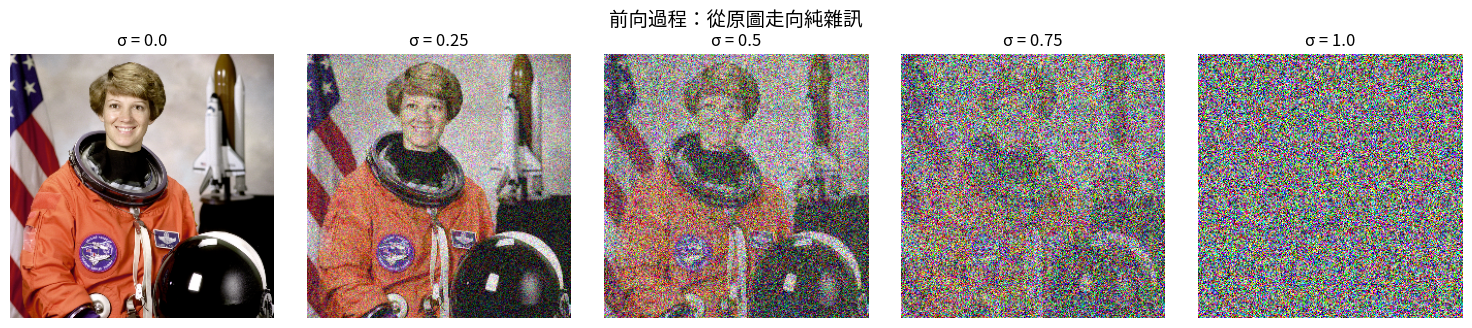

In [7]:
import numpy as np, matplotlib.pyplot as plt, torch
try:
    from skimage import data as skdata
    img = skdata.astronaut()[::2, ::2] / 255.0          # 256×256 範例圖
except Exception:
    yy, xx = np.mgrid[0:256, 0:256] / 255.0              # 沒有 skimage 就用漸層圖代替
    img = np.stack([xx, yy, 1 - xx], -1)

x0 = torch.tensor(img, dtype=torch.float32) * 2 - 1      # 像素縮放到 [-1, 1]
torch.manual_seed(0)
eps = torch.randn_like(x0)

sigmas = [0.0, 0.25, 0.5, 0.75, 1.0]
fig, axes = plt.subplots(1, len(sigmas), figsize=(15, 3.3))
for ax, s in zip(axes, sigmas):
    xs = (1 - s) * x0 + s * eps                           # ← 加噪公式就這一行
    ax.imshow(((xs + 1) / 2).clamp(0, 1).numpy()); ax.set_title(f"σ = {s}"); ax.axis("off")
plt.suptitle("前向過程：從原圖走向純雜訊", fontsize=14); plt.tight_layout(); plt.show()

> ⚠️ Colab 的 matplotlib 預設沒有中文字型，標題的中文可能顯示成方框。想修正可以跑下面這格（選做）。

In [6]:
#@title （選做）讓 matplotlib 顯示中文
!apt-get -qq install -y fonts-noto-cjk > /dev/null
import matplotlib.font_manager as fm, matplotlib as mpl
for f in fm.findSystemFonts():
    if "NotoSansCJK" in f or "NotoSerifCJK" in f:
        fm.fontManager.addfont(f)
mpl.rcParams["font.family"] = "Noto Sans CJK JP"
mpl.rcParams["axes.unicode_minus"] = False
print("✅ 完成，重新執行上面的圖就會看到中文")

✅ 完成，重新執行上面的圖就會看到中文


## 1.2 生成 = 把這條路「倒著走」

加噪容易，難的是反過來：**給一團雜訊，怎麼走回一張圖？**

把加噪公式對 $\sigma$ 微分，得到沿著這條直線移動的「速度」：

$$v = \frac{dx_\sigma}{d\sigma} = \varepsilon - x_0$$

神經網路要學的就是這個速度場 $v_\theta(x_\sigma, \sigma)$：**「現在在 $x_\sigma$，應該往哪個方向走？」**

有了速度，就能用最簡單的 **Euler 法** 從 $\sigma=1$（雜訊）一小步一小步走到 $\sigma=0$（圖）：

$$x_{\sigma_{\text{next}}} = x_\sigma + (\sigma_{\text{next}} - \sigma)\cdot v_\theta(x_\sigma, \sigma)$$

| 名詞 | 意思 |
|---|---|
| **步數（steps）** | 從 1 走到 0 切成幾段 |
| **NFE** | 呼叫神經網路幾次（Number of Function Evaluations）＝ 真正的成本 |
| **CFG** | Classifier-Free Guidance：每步多算一次「無條件」版本來加強文字控制 → NFE 變兩倍 |

一般生圖：50 步 × CFG 2 次 = **100 NFE**。SMD：**4 NFE**。快了約 25 倍。

### 🤔 為什麼不能直接走 1 步？

因為網路在 $\sigma=1$ 時只看到一團雜訊，**它不知道你要哪一張圖**，最好的猜法是「所有可能的圖的平均」→ 一片模糊。
走很多小步，網路才有機會一路修正。下一節我們會親眼看到這件事。

---
# 🧪 Part 2：親手訓練、親手蒸餾

真正的生圖模型有數十億參數，但**原理和一個 2D 小玩具完全一樣**。
我們把「圖片」換成「平面上的點」，目標分布是排成 **S M D** 三個字母的點雲。

- 一張圖 ≈ 平面上的一個點
- 「所有可能的圖」≈ 這團點雲
- 生圖 ≈ 從高斯雜訊抽一個點，用速度場把它推到字母上

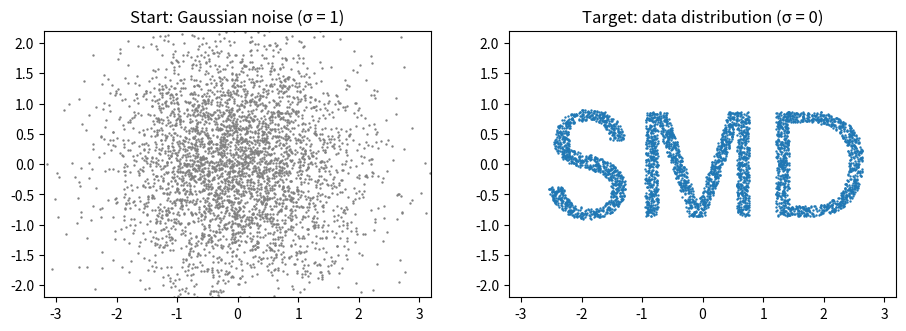

In [8]:
import math, time, copy, numpy as np, torch, torch.nn as nn, matplotlib.pyplot as plt
from PIL import Image, ImageDraw, ImageFont

device = "cuda" if torch.cuda.is_available() else "cpu"
torch.manual_seed(0); np.random.seed(0)

def make_text_points(text="SMD", n=20000):
    # 把文字畫在黑底圖上，從白色像素隨機取點
    W, H = 360, 140
    canvas = Image.new("L", (W, H), 0)
    draw = ImageDraw.Draw(canvas)
    try:
        font = ImageFont.load_default(size=120)
    except TypeError:                       # 舊版 Pillow
        font = ImageFont.load_default()
    draw.text((W // 2, H // 2), text, fill=255, font=font, anchor="mm")
    ys, xs = np.nonzero(np.array(canvas) > 128)
    idx = np.random.randint(0, len(xs), n)
    pts = np.stack([xs[idx] + np.random.rand(n), H - ys[idx] + np.random.rand(n)], 1).astype(np.float32)
    pts = (pts - pts.mean(0)) / pts.std(0).max() * 1.5
    return torch.from_numpy(pts)

data = make_text_points("SMD")    # 想換字可以改這裡，例如 "AI"、"CS"
noise_demo = torch.randn(4000, 2)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].scatter(*noise_demo.T, s=0.5, c="gray"); axes[0].set_title("Start: Gaussian noise (σ = 1)")
axes[1].scatter(*data[:4000].T, s=0.5, c="tab:blue"); axes[1].set_title("Target: data distribution (σ = 0)")
for ax in axes: ax.set_aspect("equal"); ax.set_xlim(-3.2, 3.2); ax.set_ylim(-2.2, 2.2)
plt.show()

## 2.1 速度網路與訓練（Flow Matching）

訓練超級簡單，每一輪：
1. 抽真實資料 $x_0$、抽雜訊 $\varepsilon$、抽一個隨機的 $\sigma$
2. 算出混合點 $x_\sigma = (1-\sigma)x_0 + \sigma\varepsilon$
3. 叫網路猜速度，和正確答案 $\varepsilon - x_0$ 比 MSE

這就是 FLUX、SD3 預訓練時做的事，只是它們的 $x_0$ 是圖片的 latent、網路是幾十億參數的 Transformer。

iter     0  loss 2.2885
iter  2000  loss 1.5006
iter  4000  loss 1.6038
iter  6000  loss 1.5314
✅ 老師模型訓練完成，花了 18.9 秒


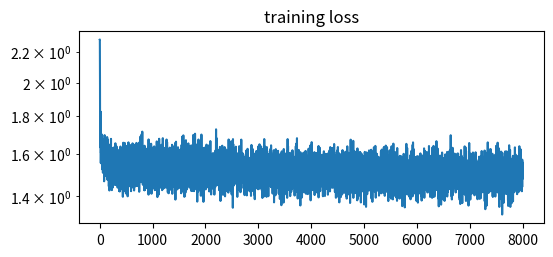

In [9]:
class VelocityNet(nn.Module):
    # 輸入 (點的位置 x, 雜訊比例 σ)，輸出速度 v
    def __init__(self, hidden=256):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(2 + 1 + 12, hidden), nn.ReLU(),
            nn.Linear(hidden, hidden), nn.ReLU(),
            nn.Linear(hidden, hidden), nn.ReLU(),
            nn.Linear(hidden, hidden), nn.ReLU(),
            nn.Linear(hidden, 2))
    def forward(self, x, sigma):
        # 把 σ 編成一組 sin/cos 特徵（就像 Transformer 的位置編碼），網路比較好分辨不同時刻
        freqs = 2.0 ** torch.linspace(0, 3, 6, device=x.device) * math.pi
        emb = sigma[:, None] * freqs[None]
        return self.net(torch.cat([x, sigma[:, None], emb.sin(), emb.cos()], dim=1))

teacher = VelocityNet().to(device)
opt = torch.optim.Adam(teacher.parameters(), lr=2e-3)
ITERS = 8000          # CPU 約 2 分鐘；GPU 約 30 秒
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, ITERS)

t0, losses = time.time(), []
for it in range(ITERS):
    x0 = data[torch.randint(0, len(data), (1024,))].to(device)
    eps = torch.randn_like(x0)
    sigma = torch.rand(1024, device=device)
    x_sigma = (1 - sigma[:, None]) * x0 + sigma[:, None] * eps     # 加噪
    loss = ((teacher(x_sigma, sigma) - (eps - x0)) ** 2).mean()   # 猜速度
    opt.zero_grad(); loss.backward(); opt.step(); sched.step()
    losses.append(loss.item())
    if it % 2000 == 0: print(f"iter {it:5d}  loss {loss.item():.4f}")
print(f"✅ 老師模型訓練完成，花了 {time.time()-t0:.1f} 秒")
plt.figure(figsize=(6, 2.5)); plt.plot(losses); plt.yscale("log"); plt.title("training loss"); plt.show()

## 2.2 用不同步數生成：看見「少步」的問題

我們用同一批起始雜訊，分別走 100、8、4、2、1 步。

另外用 **Sliced Wasserstein Distance（SWD）** 量化「生成的點雲」和「真實點雲」有多像——**越小越好**。

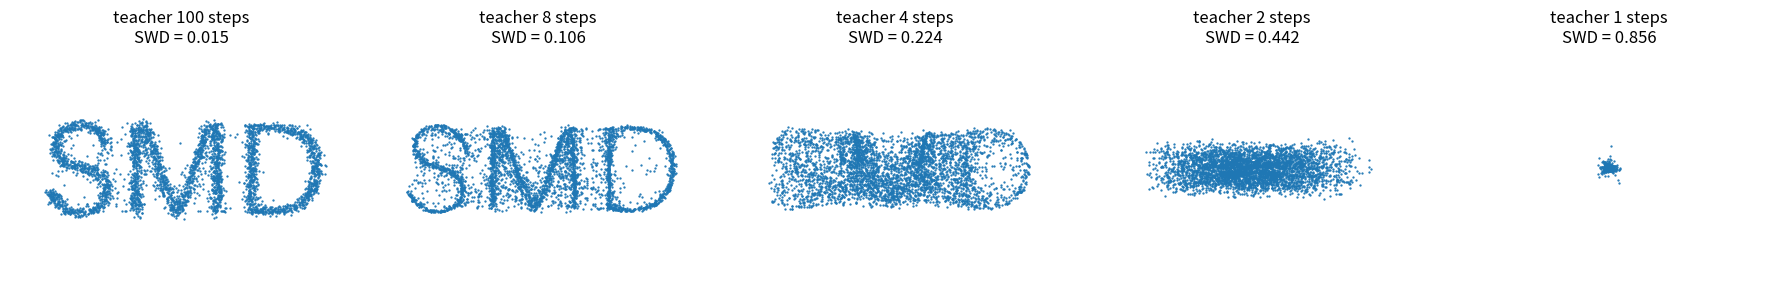

In [10]:
@torch.no_grad()
def sample_euler(model, x, sigmas, return_traj=False):
    # 沿著 sigmas（例如 [1.0, 0.75, 0.5, 0.25, 0.0]）用 Euler 法一步步走
    traj = [x.clone()]
    for s0, s1 in zip(sigmas[:-1], sigmas[1:]):
        v = model(x, torch.full((len(x),), float(s0), device=x.device))
        x = x + (s1 - s0) * v                    # ← Euler 一步
        traj.append(x.clone())
    return (x, traj) if return_traj else x

def uniform_grid(n):                             # 平均切 n 段
    return torch.linspace(1, 0, n + 1).tolist()

def swd(a, b, k=256):                            # 越小代表兩團點雲越像
    g = torch.Generator(device="cpu").manual_seed(0)
    th = torch.randn(2, k, generator=g).to(a.device); th = th / th.norm(dim=0, keepdim=True)
    pa, _ = (a @ th).sort(0); pb, _ = (b @ th).sort(0)
    return (pa - pb).abs().mean().item()

torch.manual_seed(1)
N = 4000
start_noise = torch.randn(N, 2, device=device)
ref = data[torch.randint(0, len(data), (N,))].to(device)

steps_list = [100, 8, 4, 2, 1]
fig, axes = plt.subplots(1, len(steps_list), figsize=(18, 3.4))
for ax, n in zip(axes, steps_list):
    out = sample_euler(teacher, start_noise.clone(), uniform_grid(n))
    ax.scatter(*out.cpu().T, s=0.4)
    ax.set_title(f"teacher {n} steps\nSWD = {swd(out, ref):.3f}")
    ax.set_aspect("equal"); ax.set_xlim(-3.2, 3.2); ax.set_ylim(-2.2, 2.2); ax.axis("off")
plt.tight_layout(); plt.show()

### 為什麼步數少就糊掉？看路徑就懂

下面畫出 200 個點從雜訊走到字母的**路徑**。100 步時路徑是彎的；只走幾步時，Euler 法只能用「直線」去近似彎路，就會抄近路、跑偏。
走 1 步時每個點都只能往「平均」方向衝，於是所有點擠成一團。

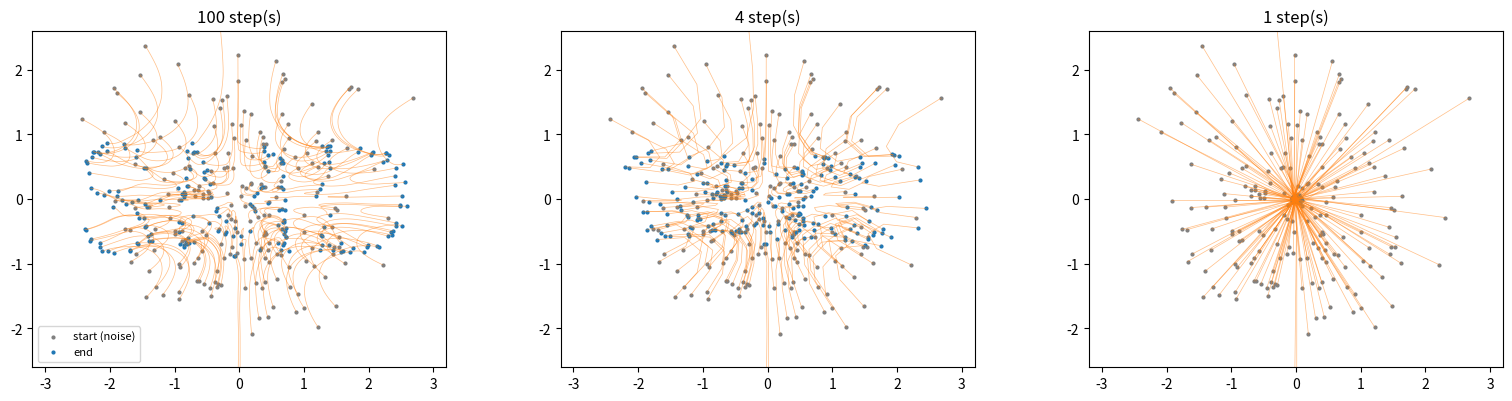

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
idx = torch.arange(200)
for ax, n in zip(axes, [100, 4, 1]):
    final, traj = sample_euler(teacher, start_noise[idx].clone(), uniform_grid(n), return_traj=True)
    T = torch.stack(traj).cpu()                    # [steps+1, 200, 2]
    for j in range(len(idx)):
        ax.plot(T[:, j, 0], T[:, j, 1], lw=0.5, alpha=0.5, c="tab:orange")
    ax.scatter(*T[0].T, s=4, c="gray", label="start (noise)")
    ax.scatter(*T[-1].T, s=4, c="tab:blue", label="end")
    ax.set_title(f"{n} step(s)"); ax.set_aspect("equal"); ax.set_xlim(-3.2, 3.2); ax.set_ylim(-2.6, 2.6)
axes[0].legend(loc="lower left", fontsize=8)
plt.tight_layout(); plt.show()

## 2.3 蒸餾：讓「學生」學會用 4 步走完老師的路

**蒸餾（distillation）** 的想法：讓已訓練好的多步模型（老師）教一個少步模型（學生）。

SMD 論文的核心主張是：**最樸素的「on-policy 速度回歸」就已經是很強的基礎**，不需要額外的分數模型（score model）或對抗訓練（GAN）。拆開來看：

| 關鍵字 | 意思 | 在下面程式碼的哪裡 |
|---|---|---|
| **4 步網格** | 學生只在固定的 4 個 σ 位置做預測 | `smd_raw_grid(4)` |
| **最後一段縮半** | SMD 釋出的取樣器把最後一段的步長設為一般的 **0.5 倍**（final-segment scale 0.5） | `final=0.5` |
| **區間平均速度** | 學生一步要跨過一大段，所以它該學的不是「此刻的速度」，而是**整段區間的平均速度**＝老師用很多小步實際走完這段的位移 ÷ 區間長度 | `tgt = (x_teacher_end - x) / (s1 - s0)` |
| **On-policy** | 訓練時的輸入狀態，是**學生自己一路走出來的**，不是從資料加噪來的。學生會在自己真正會遇到的地方被糾正 | `x = x + (s1-s0) * student(...)` |
| **回歸（regression）** | 損失就是簡單的 MSE，沒有 GAN | `loss = MSE` |

> 📌 **誠實說明**：這是**教學用的簡化版**，只保留「on-policy 區間平均速度回歸」這個骨幹。
> 論文另外還有兩個關鍵設計：**Pivot**（訓練時用來表示區間內老師速度變化的殘差代理）和**排斥較弱的老師預測**（避開不想要的模式），這裡沒有實作。
> 此外部署時學生的架構和老師一模一樣——這也是 SMD 可以用 LoRA 或直接替換權重釋出的原因。

In [12]:
def smd_raw_grid(n, final=0.5):
    # SMD 釋出取樣器的原始網格：前 n-1 段等長，最後一段是 final 倍
    size = 1.0 / (n - 1 + final)
    v = [1.0]
    for i in range(n):
        v.append(v[-1] - size * (final if i == n - 1 else 1.0))
    v[-1] = 0.0
    return v

grid4 = smd_raw_grid(4)
print("SMD 4 步網格（還沒加 shift）:", [round(s, 3) for s in grid4])
print("一般均分 4 步網格          :", uniform_grid(4))

SMD 4 步網格（還沒加 shift）: [1.0, 0.714, 0.429, 0.143, 0.0]
一般均分 4 步網格          : [1.0, 0.75, 0.5, 0.25, 0.0]


In [13]:
student = copy.deepcopy(teacher)              # 學生從老師的權重出發
opt = torch.optim.Adam(student.parameters(), lr=3e-4)
SUBSTEPS = 8                                  # 老師在每段區間內用 8 小步走，當作「標準答案」
DISTILL_ITERS = 1000                          # CPU 約 2 分鐘
B = 1024

t0, dlosses = time.time(), []
for it in range(DISTILL_ITERS):
    x = torch.randn(B, 2, device=device)
    states, sig_in, targets = [], [], []
    with torch.no_grad():
        for s0, s1 in zip(grid4[:-1], grid4[1:]):
            # (1) 老師：從學生目前所在的位置，用很多小步走完這段 → 算出區間平均速度
            x_teacher_end = sample_euler(teacher, x.clone(), torch.linspace(s0, s1, SUBSTEPS + 1).tolist())
            target_v = (x_teacher_end - x) / (s1 - s0)
            states.append(x); sig_in.append(torch.full((B,), s0, device=device)); targets.append(target_v)
            # (2) On-policy：下一段的起點，是「學生自己」走一步的結果
            x = x + (s1 - s0) * student(x, torch.full((B,), s0, device=device))
    X, S, T = torch.cat(states), torch.cat(sig_in), torch.cat(targets)
    loss = ((student(X, S) - T) ** 2).mean()  # (3) 純回歸
    opt.zero_grad(); loss.backward(); opt.step()
    dlosses.append(loss.item())
    if it % 300 == 0: print(f"iter {it:5d}  distill loss {loss.item():.4f}")
print(f"✅ 蒸餾完成，花了 {time.time()-t0:.1f} 秒")

iter     0  distill loss 0.0756
iter   300  distill loss 0.0013
iter   600  distill loss 0.0005
iter   900  distill loss 0.0003
✅ 蒸餾完成，花了 20.7 秒


## 2.4 驗收：學生 4 步 vs 老師

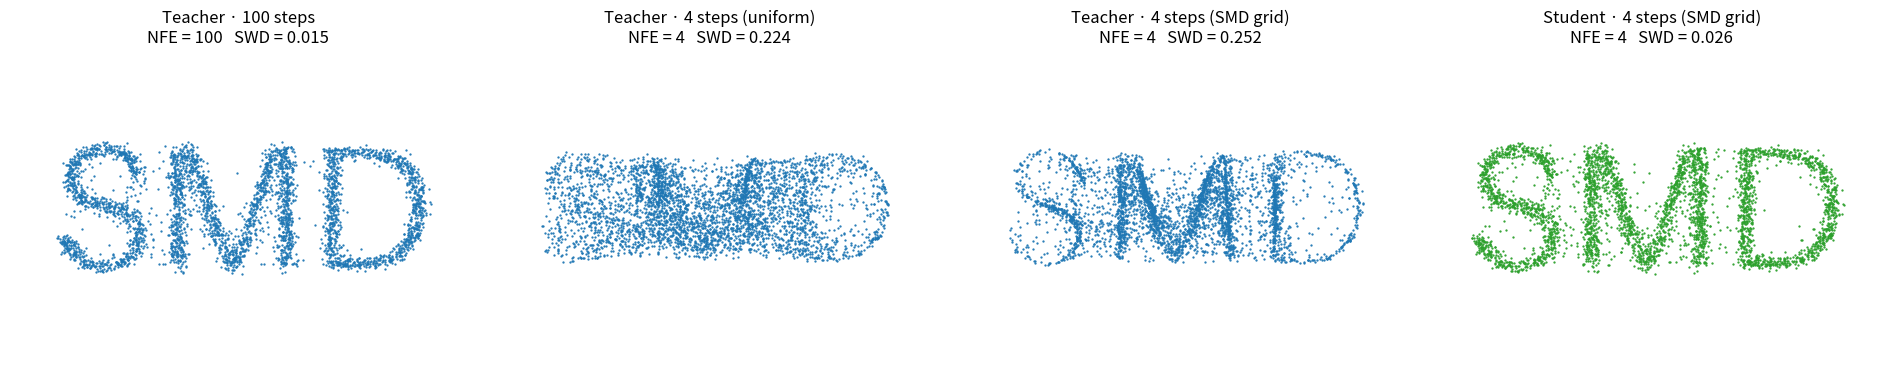

In [14]:
runs = [
    ("Teacher · 100 steps",          teacher, uniform_grid(100)),
    ("Teacher · 4 steps (uniform)",  teacher, uniform_grid(4)),
    ("Teacher · 4 steps (SMD grid)", teacher, grid4),
    ("Student · 4 steps (SMD grid)", student, grid4),
]
fig, axes = plt.subplots(1, 4, figsize=(19, 3.6))
for ax, (name, m, g) in zip(axes, runs):
    out = sample_euler(m, start_noise.clone(), g)
    ax.scatter(*out.cpu().T, s=0.4, c="tab:green" if "Student" in name else "tab:blue")
    ax.set_title(f"{name}\nNFE = {len(g)-1}   SWD = {swd(out, ref):.3f}")
    ax.set_aspect("equal"); ax.set_xlim(-3.2, 3.2); ax.set_ylim(-2.2, 2.2); ax.axis("off")
plt.tight_layout(); plt.show()

### ✍️ 動手改改看（Part 2 小作業）

1. 把 `make_text_points("SMD")` 換成你的名字縮寫，重跑整個 Part 2。
2. 把 `smd_raw_grid(4)` 改成 `smd_raw_grid(2)`（2 步學生），效果怎麼樣？1 步呢？
3. 把 `final=0.5` 改成 `1.0`（等長網格），SWD 有沒有變化？
4. **關掉 on-policy**：把迴圈裡「學生自己走一步」那行改成「老師走的位置」`x = x_teacher_end`，比較結果。想想看：為什麼讓學生在**自己會犯錯的地方**被糾正比較好？

---
# 🏗️ Part 3：從玩具到真正的生圖模型

剛剛的玩具，和 FLUX.2 [klein] 4B 其實是同一套數學。差別只在「規模」與「條件」：

| | Part 2 玩具 | FLUX.2 [klein] 4B |
|---|---|---|
| 一筆「資料」 | 平面上的 1 個點（2 個數字） | 一張 1024×1024 圖的 **latent**：128 通道 × 64 × 64 ≈ 52 萬個數字 |
| 為什麼用 latent | — | 直接在像素上跑太貴，所以先用 **VAE** 壓縮，生成完再解碼回圖片（Latent Diffusion） |
| 速度網路 | 5 層 MLP，約 20 萬參數 | **Transformer**，約 40 億參數 |
| 條件 | 無 | 文字提示詞 → **Qwen3 文字編碼器** 轉成向量，餵給 Transformer |
| 取樣 | Euler 法 | 一樣是 Euler 法（`FlowMatchEulerDiscreteScheduler`） |
| 時間軸 | 均勻 | 加上 **time shift**：讓步數集中在高雜訊區，解析度越高 shift 越大 |
| 步數 | 100 步 | 原始模型建議 **50 步 + CFG**（≈100 NFE） |
| SMD 學生 | 4 步 | **4 步、無 CFG**（4 NFE），以 LoRA 形式釋出 |

### SMD 論文重點（arXiv:2610.18472，2026/10）

- 少步蒸餾常需要額外的**分數模型**或**特殊架構**；SMD 證明簡單的 **on-policy 速度回歸**就是 4 步生成的強基礎。
- 加上 **Pivot**（只在訓練時用的殘差代理，把區間內的局部修正和學生的區間平均預測分開）與**排斥較弱老師預測**的機制。
- 全程只用回歸：**不需要線上分數估計、不需要對抗訓練**，部署的生成器架構不變。
- 套用在圖片生成與編輯、3D、影片、音訊+影片，最大到 330 億參數；4 步就能勝過其他少步方法，在部分基準上甚至超越多步老師。

### SMD 釋出的生圖模型

| 模型 | 格式 | 適合 Colab？ |
|---|---|---|
| **FLUX.2 Klein 4B** | LoRA（0.58 GB）+ Apache-2.0 基底 | ✅ **本筆記本使用** |
| SD3.5-Medium | 完整 Transformer（4.94 GB） | ⚠️ 基底需同意授權條款、T5 編碼器很大 |
| FLUX.1-dev / Qwen-Image / Lens | LoRA | ❌ 基底模型太大 |

FLUX.2 Klein 4B 的 SMD 有兩個版本：`teacher-4b`（用 4B 模型自己當老師）與 `teacher-9b`（用更大的 9B 模型當老師，**跨模型蒸餾**）。學生都是同一個 4B 模型。

---
# 🚀 Part 4：跑 SMD-FLUX.2-Klein-4B

流程：

1. 下載 SMD 的 LoRA、取樣設定與官方推論工具
2. 看 SMD 的 4 步 σ 網格長什麼樣
3. **階段 A**：只載文字編碼器 → 把提示詞轉成向量 → 釋放記憶體
4. **階段 B**：只載 Transformer + VAE
5. 原始模型：4 步（沒蒸餾）vs 多步 + CFG
6. 融合 SMD LoRA → 4 步生圖，並看每一步「模型心中的答案」
7. 自己下提示詞

> 🔐 **關於 Hugging Face Token**：本節使用的模型都是公開、免授權閘門的，**不需要 token**。
> 如果之後要用需要登入的模型，請放在 Colab 左側欄的 **🔑 密鑰（Secrets）**，用 `userdata.get("HF_TOKEN")` 讀取——
> **絕對不要把 token 直接寫在筆記本裡**，分享筆記本時它會跟著外流（呼應上週的金鑰安全守則）。

In [15]:
#@title 4.1 參數設定
VARIANT = "teacher-9b"   #@param ["teacher-9b", "teacher-4b"]
HEIGHT = 1024            #@param {type:"integer"}
WIDTH = 1024             #@param {type:"integer"}
BASE_STEPS = 28          #@param {type:"integer"}
BASE_CFG = 4.0           #@param {type:"number"}
SEED = 1234              #@param {type:"integer"}
PROMPT = "A brown leather luggage tag embossed with \"SMD\" in large uppercase letters, written horizontally. The tag hangs from a silver suitcase handle. Close-up travel photography, warm airport window light."  #@param {type:"string"}

assert HEIGHT % 16 == 0 and WIDTH % 16 == 0, "長寬必須是 16 的倍數"
print("SMD 是在 1024×1024 下訓練與驗證的；改成較小尺寸可以加速，但品質可能下降。")
print("BASE_STEPS 是原始模型（對照組）的步數，官方建議 50；設 28 是為了省時間。")

SMD 是在 1024×1024 下訓練與驗證的；改成較小尺寸可以加速，但品質可能下降。
BASE_STEPS 是原始模型（對照組）的步數，官方建議 50；設 28 是為了省時間。


In [16]:
#@title 4.2 下載 SMD LoRA 與官方推論工具（約 1.2 GB）
import os, sys, json, time, gc
from pathlib import Path
import numpy as np, matplotlib.pyplot as plt, torch
from huggingface_hub import snapshot_download

SMD_DIR = Path(snapshot_download(
    "zjwfufu/SMD-FLUX.2-Klein-4B",
    local_dir="SMD-FLUX.2-Klein-4B",
    # 舊路徑的 lora.safetensors 和根目錄的權重檔一模一樣，不重複下載
    ignore_patterns=["teacher-4b/lora/lora.safetensors", "teacher-9b/lora/lora.safetensors"],
))
sys.path.insert(0, str(SMD_DIR))
from inference_utils import StudentEulerScheduler, fuse_adapter, sigma_grid   # 官方 Apache-2.0 程式碼

spec = json.loads((SMD_DIR / VARIANT / "sampling.json").read_text())
print("SMD 取樣設定 sampling.json：")
print(json.dumps(spec, indent=2, ensure_ascii=False))

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 18 files:   0%|          | 0/18 [00:00<?, ?it/s]

SMD 取樣設定 sampling.json：
{
  "schema_version": "1.0",
  "network_family": "flux2",
  "model_id": "black-forest-labs/FLUX.2-klein-base-4B",
  "precision": "bfloat16",
  "weights": "lora/lora.safetensors",
  "sampler": {
    "type": "flow_match_euler_student",
    "student_sample_steps": 4,
    "final_step_size_scale": 0.5,
    "embedded_guidance_scale": null,
    "input_shape": [
      128,
      64,
      64
    ]
  },
  "noise_scheduler": {
    "type": "flow_match_euler",
    "schedule_type": "rf",
    "network_family": "flux2",
    "dynamic_shift": true,
    "base_shift": 0.5,
    "max_shift": 1.15,
    "base_seq_len": 256,
    "max_seq_len": 4096,
    "empirical_steps": 50,
    "time_shift_type": "exponential",
    "max_t": 0.999,
    "min_t": 0.0
  },
  "base_model_revision": "a3b4f4849157f664bdbc776fd7453c2783562f4d"
}


## 4.3 SMD 的 4 步 σ 網格

Part 2 的 `smd_raw_grid` 再加上 FLUX.2 的 **time shift**，就是 SMD 實際用的 σ 網格。
shift 會把均勻的格點往高雜訊那端推：大部分的「步數預算」花在決定構圖的早期階段。

raw grid  : [1.     0.7143 0.4286 0.1429 0.    ]
SMD sigmas: [0.999  0.932  0.8044 0.4776 0.    ]


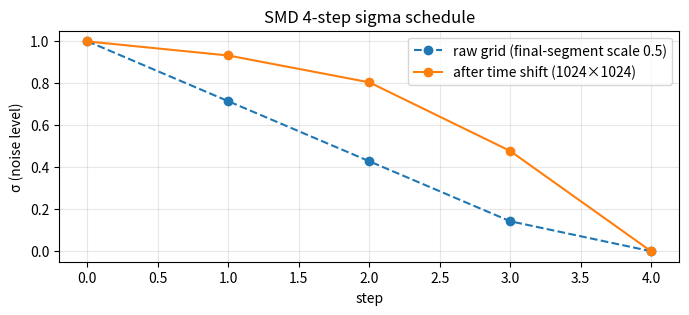

In [17]:
n, final = spec["sampler"]["student_sample_steps"], spec["sampler"]["final_step_size_scale"]
size = 1.0 / (n - 1 + final)                   # 和 Part 2 的 smd_raw_grid 相同
raw = np.array([1.0 - size * min(i, n - 1) - (size * final if i == n else 0) for i in range(n + 1)])
raw[-1] = 0.0
smd_grid = sigma_grid(spec, HEIGHT, WIDTH)     # 官方函式：raw grid → time shift
print("raw grid  :", np.round(raw, 4))
print("SMD sigmas:", np.round(smd_grid.numpy(), 4))

plt.figure(figsize=(8, 3))
plt.plot(range(len(raw)), raw, "o--", label="raw grid (final-segment scale 0.5)")
plt.plot(range(len(smd_grid)), smd_grid.numpy(), "o-", label=f"after time shift ({HEIGHT}×{WIDTH})")
plt.xlabel("step"); plt.ylabel("σ (noise level)"); plt.legend(); plt.grid(alpha=0.3)
plt.title("SMD 4-step sigma schedule"); plt.show()

## 4.4 階段 A：文字編碼

FLUX.2 [klein] 用 **Qwen3** 語言模型當文字編碼器（約 8 GB）。我們只載它、把提示詞（和 CFG 需要的空白提示詞）轉成向量，然後立刻釋放。
第一次執行會下載基底模型，約需數分鐘。

In [18]:
import gc, torch
from diffusers import Flux2KleinPipeline

BASE_ID = spec.get("model_id", "black-forest-labs/FLUX.2-klein-base-4B")
BASE_REV = spec.get("base_model_revision")         # SMD 指定的基底版本，確保可重現
DTYPE = torch.bfloat16
rev_kw = {"revision": BASE_REV} if BASE_REV else {}

def free():
    gc.collect(); torch.cuda.empty_cache()
    print(f"GPU 已用 {torch.cuda.memory_allocated()/1024**3:.1f} GB")

@torch.no_grad()
def encode_prompts(prompts):
    # 只載文字編碼器（transformer / vae 設為 None 就不會載入）
    # device_map="cuda"：權重直接串流進 GPU，不必先在 CPU 記憶體放一整份
    kw = dict(transformer=None, vae=None, torch_dtype=DTYPE, **rev_kw)
    try:
        te = Flux2KleinPipeline.from_pretrained(BASE_ID, device_map="cuda", **kw)
    except Exception as e:
        print("device_map 載入失敗，改用一般載入：", type(e).__name__)
        te = Flux2KleinPipeline.from_pretrained(BASE_ID, **kw).to("cuda")
    out = {p: te.encode_prompt(prompt=p, device="cuda")[0].cpu() for p in prompts}
    del te; free()
    return out

embeds = encode_prompts([PROMPT, ""])
print("prompt_embeds 形狀:", tuple(embeds[PROMPT].shape), "← [batch, token 數, 特徵維度]")

Flax classes are deprecated and will be removed in Diffusers v1.0.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.
Flax classes are deprecated and will be removed in Diffusers v1.0.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.


model_index.json:   0%|          | 0.00/422 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 13 files:   0%|          | 0/13 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/3 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

GPU 已用 0.0 GB
prompt_embeds 形狀: (1, 512, 7680) ← [batch, token 數, 特徵維度]


## 4.5 階段 B：載入 Transformer 與 VAE

In [19]:
def load_denoiser():
    # 不載文字編碼器；這裡不用 device_map，之後才能用 .to() 在 CPU / GPU 之間搬動
    p = Flux2KleinPipeline.from_pretrained(BASE_ID, text_encoder=None, tokenizer=None,
                                           torch_dtype=DTYPE, **rev_kw).to("cuda")
    p.set_progress_bar_config(disable=False)
    return p

pipe = load_denoiser()
base_scheduler = pipe.scheduler                   # 先存起來，之後原始模型要用
n_params = sum(p.numel() for p in pipe.transformer.parameters())
print(f"Transformer 參數量：{n_params/1e9:.2f} B")
free()

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 6 files:   0%|          | 0/6 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/3 [00:00<?, ?it/s]

Transformer 參數量：3.88 B
GPU 已用 7.4 GB


### 小工具：把 latent 解碼成圖片

我們想看「每一步模型心中的答案」。由 $x_\sigma = (1-\sigma)x_0 + \sigma\varepsilon$ 和 $v = \varepsilon - x_0$ 可以推出：

$$\hat{x}_0 = x_\sigma - \sigma \cdot v_\theta(x_\sigma, \sigma)$$

也就是「如果現在一步跳到終點，會得到什麼圖」。下面的 `RecordingScheduler` 在每一步把 $\hat{x}_0$ 記下來。

In [20]:
from diffusers import FlowMatchEulerDiscreteScheduler

@torch.no_grad()
def decode_packed(pipe, packed, height, width):
    # 把 Transformer 用的「打包 latent」[B, H*W, 128] 還原成圖片（和 pipeline 最後的解碼步驟相同）
    lh, lw = height // 16, width // 16
    lat = packed.view(packed.shape[0], lh, lw, -1).permute(0, 3, 1, 2)
    mean = pipe.vae.bn.running_mean.view(1, -1, 1, 1).to(lat)
    std = torch.sqrt(pipe.vae.bn.running_var.view(1, -1, 1, 1) + pipe.vae.config.batch_norm_eps).to(lat)
    lat = pipe._unpatchify_latents(lat * std + mean)
    img = pipe.vae.decode(lat.to(pipe.vae.dtype), return_dict=False)[0]
    return pipe.image_processor.postprocess(img, output_type="pil")[0]

class RecordingScheduler(StudentEulerScheduler):
    # 和官方 StudentEulerScheduler 完全相同，只是多記錄每一步的 x0 預測
    def step(self, model_output, timestep, sample, return_dict=True, **kwargs):
        if self.step_index is None:
            self._init_step_index(timestep)
        sigma = self.sigmas[self.step_index].to(sample.dtype)
        self.x0_preds.append((sample - sigma * model_output.to(sample.dtype)).detach())
        return super().step(model_output, timestep, sample, return_dict=return_dict, **kwargs)

def show_row(images, titles, size=4):
    fig, axes = plt.subplots(1, len(images), figsize=(size * len(images), size + 0.6))
    axes = np.atleast_1d(axes)
    for ax, im, t in zip(axes, images, titles):
        ax.imshow(im); ax.set_title(t, fontsize=10); ax.axis("off")
    plt.tight_layout(); plt.show()

def timed(fn):
    torch.cuda.synchronize(); t = time.time(); out = fn(); torch.cuda.synchronize()
    return out, time.time() - t

## 4.6 對照組：原始 FLUX.2 [klein] 基底模型

先看兩件事：
- **原始模型只走 4 步**會怎樣？（對應 Part 2「老師 4 步」）
- 原始模型走 `BASE_STEPS` 步 + CFG（正常用法）要花多久？

  0%|          | 0/4 [00:00<?, ?it/s]

  0%|          | 0/28 [00:00<?, ?it/s]

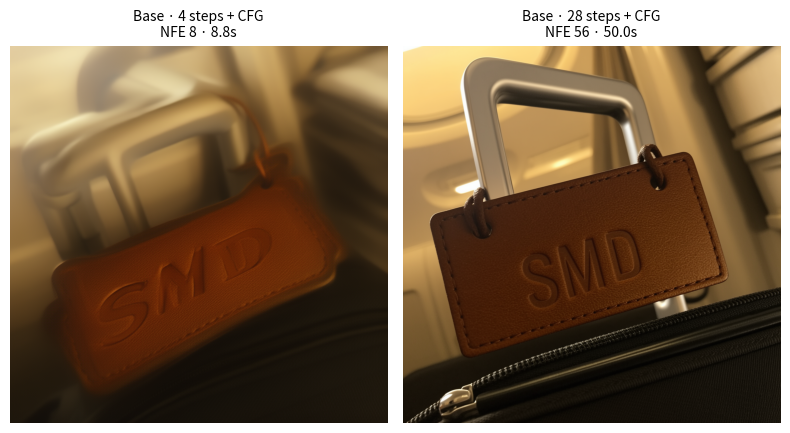

In [21]:
import time
pe, ne = embeds[PROMPT].to("cuda"), embeds[""].to("cuda")

def run_base(steps, cfg):
    pipe.scheduler = base_scheduler
    g = torch.Generator("cuda").manual_seed(SEED)
    return pipe(prompt_embeds=pe, negative_prompt_embeds=ne, height=HEIGHT, width=WIDTH,
                num_inference_steps=steps, guidance_scale=cfg, generator=g).images[0]

img_base4, t_base4 = timed(lambda: run_base(4, BASE_CFG))
base4_sigmas = pipe.scheduler.sigmas.cpu().numpy()
img_base, t_base = timed(lambda: run_base(BASE_STEPS, BASE_CFG))
base_sigmas = pipe.scheduler.sigmas.cpu().numpy()

nfe = lambda steps, cfg: steps * (2 if cfg > 1 else 1)
show_row([img_base4, img_base],
         [f"Base · 4 steps + CFG\nNFE {nfe(4, BASE_CFG)} · {t_base4:.1f}s",
          f"Base · {BASE_STEPS} steps + CFG\nNFE {nfe(BASE_STEPS, BASE_CFG)} · {t_base:.1f}s"])

## 4.7 融合 SMD LoRA

`fuse_adapter` 是 SMD 官方的融合函式：把 LoRA 的低秩矩陣 $B A$ 乘開、乘上縮放係數，**直接加進原本的權重**（$W \leftarrow W + \alpha \cdot BA$），另外還會換上一些 SMD 存下來的替換張量。
融合後模型架構完全沒變——這正是論文說「部署的生成器不變」的意思。

> ⚠️ 融合是**就地修改**權重，之後 `pipe` 就變成 SMD 學生了。想回到原始模型，重新執行 4.5 即可。

In [22]:
info = fuse_adapter(pipe.transformer, SMD_DIR / VARIANT / "lora")
print("SMD adapter 已融合：", info)   # pairs = LoRA 矩陣對數量；replacements = 直接替換的張量數

SMD adapter 已融合： {'pairs': 51, 'replacements': 1}


## 4.8 SMD：4 步生圖

起始雜訊的產生方式和官方 `infer.py` 完全相同（形狀 `[1, 128, H/16, W/16]`、乘上 σ 網格的第一個值），所以同樣的 seed 應該會得到和官方範例非常接近的圖（不同 GPU 可能有極小的數值差異）。

  0%|          | 0/4 [00:00<?, ?it/s]

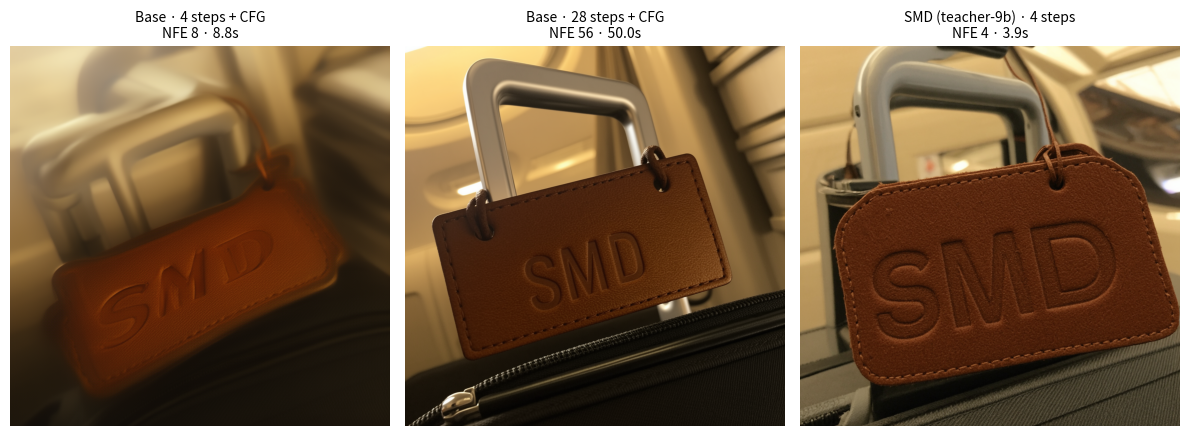

⏱️ SMD 比 28 步原始模型快約 12.8 倍


In [23]:
def run_smd(prompt_embeds, seed, height=HEIGHT, width=WIDTH):
    grid = sigma_grid(spec, height, width)
    pipe.scheduler = RecordingScheduler.from_config(base_scheduler.config).configure(grid)
    pipe.scheduler.x0_preds = []
    g = torch.Generator("cuda").manual_seed(seed)
    noise = torch.randn([1, 128, height // 16, width // 16], device="cuda", dtype=DTYPE, generator=g)
    noise = (noise.double() * grid[0].to("cuda")).to(DTYPE)
    out = pipe(prompt_embeds=prompt_embeds, height=height, width=width,
               num_inference_steps=spec["sampler"]["student_sample_steps"],
               guidance_scale=spec["sampler"].get("embedded_guidance_scale") or 1.0,  # SMD 學生不用外部 CFG
               generator=g, latents=noise).images[0]
    return out, grid

(img_smd, smd_grid_used), t_smd = timed(lambda: run_smd(pe, SEED))
show_row([img_base4, img_base, img_smd],
         [f"Base · 4 steps + CFG\nNFE {nfe(4, BASE_CFG)} · {t_base4:.1f}s",
          f"Base · {BASE_STEPS} steps + CFG\nNFE {nfe(BASE_STEPS, BASE_CFG)} · {t_base:.1f}s",
          f"SMD ({VARIANT}) · 4 steps\nNFE 4 · {t_smd:.1f}s"])
print(f"⏱️ SMD 比 {BASE_STEPS} 步原始模型快約 {t_base / t_smd:.1f} 倍")

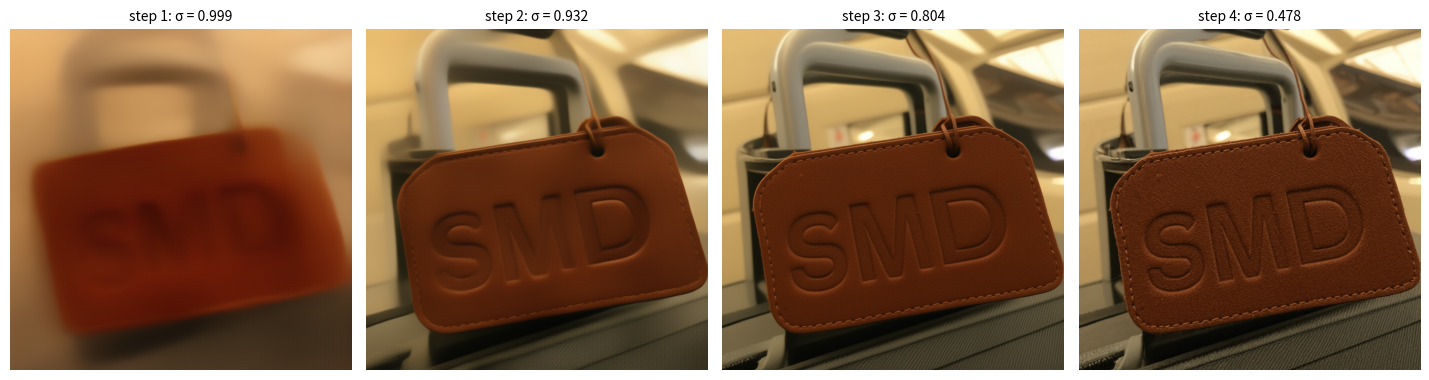

觀察：第 1 步就已經決定構圖與主體，後面幾步主要在補細節與文字。


In [24]:
#@title 每一步「模型心中的答案」x̂₀
x0_imgs = [decode_packed(pipe, x, HEIGHT, WIDTH) for x in pipe.scheduler.x0_preds]
show_row(x0_imgs, [f"step {i+1}: σ = {s:.3f}" for i, s in enumerate(smd_grid_used[:-1].tolist())], size=3.6)
print("觀察：第 1 步就已經決定構圖與主體，後面幾步主要在補細節與文字。")

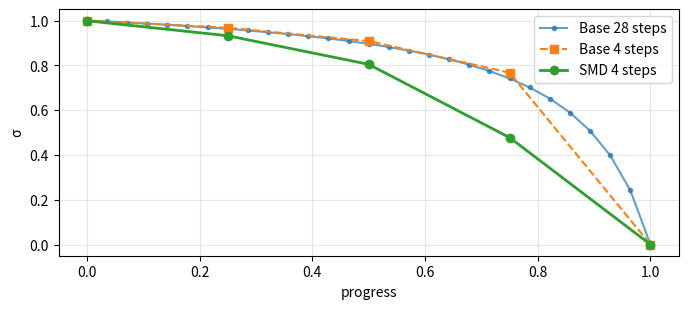

In [25]:
#@title σ 排程比較：原始模型 vs SMD
plt.figure(figsize=(8, 3.2))
plt.plot(np.linspace(0, 1, len(base_sigmas)), base_sigmas, ".-", label=f"Base {BASE_STEPS} steps", alpha=0.7)
plt.plot(np.linspace(0, 1, len(base4_sigmas)), base4_sigmas, "s--", label="Base 4 steps")
plt.plot(np.linspace(0, 1, len(smd_grid_used)), smd_grid_used.numpy(), "o-", lw=2, label="SMD 4 steps")
plt.xlabel("progress"); plt.ylabel("σ"); plt.legend(); plt.grid(alpha=0.3); plt.show()

## 4.9 換你出題！

每次換提示詞，都要先用文字編碼器轉成向量（約 30 秒，因為要暫時載入 Qwen3），之後同一個提示詞換 seed 都很快。

**提示詞小技巧**：用英文、描述「主體 + 場景 + 光線 + 風格」；想要字出現在圖上，就把字用引號包起來，例如 `a neon sign that says "OPEN"`。

GPU 已用 0.0 GB


Loading pipeline components...:   0%|          | 0/3 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

GPU 已用 0.0 GB


  0%|          | 0/4 [00:00<?, ?it/s]

  0%|          | 0/4 [00:00<?, ?it/s]

  0%|          | 0/4 [00:00<?, ?it/s]

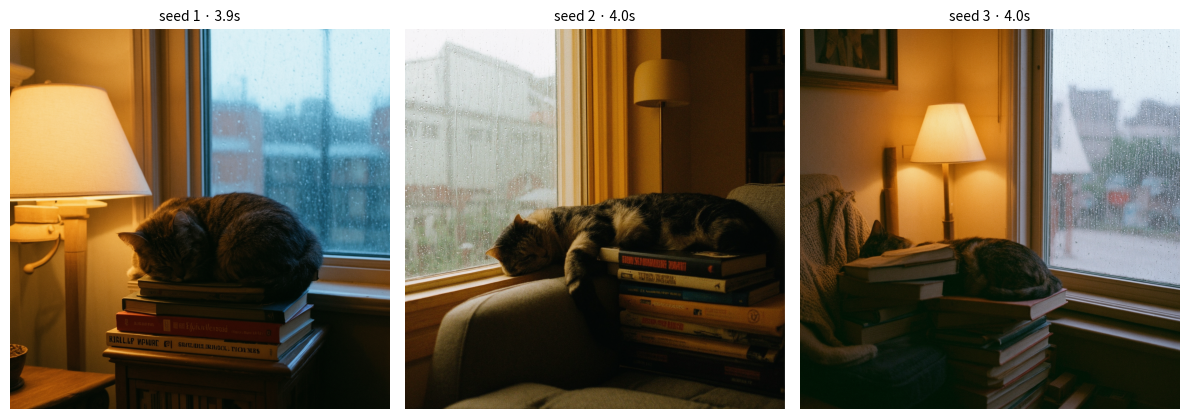

圖片已存在左側檔案區 smd_<seed>.png


In [26]:
#@title 自訂生圖
MY_PROMPT = "A cozy reading nook by a rainy window, a cat sleeping on a stack of books, warm lamp light, film photography"  #@param {type:"string"}
SEEDS = "1, 2, 3"  #@param {type:"string"}
MY_SIZE = "1024x1024"  #@param ["1024x1024", "1152x896", "896x1152", "1344x768", "768x1344"]

w, h = map(int, MY_SIZE.split("x"))
if MY_PROMPT not in embeds:
    free_gb = torch.cuda.mem_get_info()[0] / 1024**3
    if free_gb < 10:
        # GPU 放不下兩個模型（例如 T4）：暫時把 Transformer 移到 CPU，騰出空間給文字編碼器
        pipe.to("cpu"); free()
        embeds.update(encode_prompts([MY_PROMPT]))
        pipe.to("cuda")
    else:
        embeds.update(encode_prompts([MY_PROMPT]))

imgs, titles = [], []
for s in [int(x) for x in SEEDS.split(",")]:
    (im, _), t = timed(lambda: run_smd(embeds[MY_PROMPT].to("cuda"), s, h, w))
    imgs.append(im); titles.append(f"seed {s} · {t:.1f}s")
    im.save(f"smd_{s}.png")
show_row(imgs, titles)
print("圖片已存在左側檔案區 smd_<seed>.png")

### （選做）官方一行指令

SMD 的 Hugging Face 套件也附了獨立的 `infer.py`，在記憶體充足的環境（例如 A100 高 RAM）可以直接：

```bash
!cd SMD-FLUX.2-Klein-4B && python infer.py --variant teacher-9b --output outputs --prompt "your prompt" --seed 42
```

它會一次載入整個 pipeline（文字編碼器 + Transformer），再用 CPU offload 輪流上 GPU，所以需要比較多的系統記憶體；本筆記本的「分兩階段載入」就是為了避開這個限制。

---
# 📝 Part 5：總結

| 你學到的 | 一句話 |
|---|---|
| 擴散 / Flow Matching | 在「圖」與「雜訊」之間畫直線，訓練網路預測沿線的速度 |
| 取樣 | 從雜訊出發，用 Euler 法沿速度一步步走回圖 |
| 少步的難處 | 真實路徑是彎的，大步走會偏；1 步只能得到平均（模糊） |
| 蒸餾 | 讓學生學會「一大步 = 老師很多小步的總位移」（區間平均速度） |
| On-policy | 在學生**自己會走到的地方**糾正它 |
| SMD | 用純回歸就把 4 步做到很強，不需要分數模型或 GAN；部署架構不變 |
| 工程 | latent + VAE、文字編碼器、time shift、LoRA 融合、記憶體分階段載入 |

## 🤔 思考題

1. 4 步生圖快了很多倍，那**代價**是什麼？比較原始模型與 SMD 的圖，在多樣性、細節、文字正確性上有沒有差？（提示：多試幾個 seed）
2. SMD 的 `teacher-9b` 版本是用**比學生大的模型**當老師。為什麼學生有可能「青出於藍」超越同尺寸的多步模型？
3. 如果要把 4 步生圖做成一個網站（呼應上週的 AI Studio + Cloudflare），每張圖的成本、等待時間、伺服器需求會怎麼改變？

## 📚 參考資料

- SMD 程式碼：[github.com/zjwfufu/SMD](https://github.com/zjwfufu/SMD)（Apache-2.0）
- 論文：Zhang et al., *Simplifying and Improving On-Policy Distillation for Few-Step Diffusion*, [arXiv:2610.18472](https://arxiv.org/abs/2610.18472)
- 專案頁：[zjwfufu.github.io/SMD-Page](https://zjwfufu.github.io/SMD-Page/)
- 模型：[zjwfufu/SMD-FLUX.2-Klein-4B](https://huggingface.co/zjwfufu/SMD-FLUX.2-Klein-4B)；基底 [black-forest-labs/FLUX.2-klein-base-4B](https://huggingface.co/black-forest-labs/FLUX.2-klein-base-4B)（Apache-2.0）
- Flow Matching 入門：Lipman et al., *Flow Matching for Generative Modeling* (2022)；Liu et al., *Rectified Flow* (2022)
- [Hugging Face Diffusers 文件](https://huggingface.co/docs/diffusers)

> ⚖️ **負責任使用**：生成的圖片請標示為 AI 生成；不得用於冒充真人、散布不實資訊或侵害他人權利。FLUX.2 [klein] 4B 的使用規範詳見其模型卡。

**Keep Creating, Keep Learning** 🔥